# Week 4: Scaling Up the cis-eQTL Analysis and Predicting Gene Expression

## This week at a glance

**Big idea:** Last week I tested one gene. This week I test every gene on a chromosome, then I go one step further: I use the eQTL results to **predict** a person's gene expression from their genotype alone. This is a polygenic score, just like a PRS for a disease, except the "trait" is how much a gene is expressed. To check the prediction honestly, I test it on people the model never saw.

**My readings**
| Paper | What I read | Why it matters |
|---|---|---|
| GTEx Consortium 2020, *Science* | Reread, plus (optional) the Supplementary methods | The analysis my project replicates, so I compare their methods to mine |

**My tasks**
1. Run a cis-eQTL analysis for all genes on one chromosome (I use chromosome 5).
2. Build a PRS with pruning and thresholding (P+T), following the PLINK PRS tutorial, with eQTL results in place of a GWAS.
3. Cross-validate the score for one gene:
   - Fit on a random 80% of people
   - Pick the best p-value threshold (1, 0.05, 0.01, 0.001, 0.00001) on half of the rest
   - Report R^2 on the last group, who were never used for fitting

**Weekly questions I answer on Gradescope**
1. What is the biological purpose of understanding how genetic variation affects gene expression?
2. What would be a good title for a paper on this capstone analysis?
3. What should the paper's introduction cover?
4. What was the distribution of correlations between true and predicted gene expression across genes in 1000 Genomes?

**My data**
- Genotypes: 1000 Genomes European samples (`../data/raw/LDREF/`)
- Gene expression: Geuvadis blood cell RNA-seq (`../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt`)
- My chromosome: **5**. My example gene: **ERAP2** (from Week 3)

## Biology background and vocabulary

### From one gene to every gene

Week 3 was one gene (ERAP2) and its 510 nearby SNPs. Now I repeat that for every gene on chromosome 5. Each gene gets its own cis window, its own set of tests, and its own Bonferroni cutoff (0.05 / number of SNPs in that gene's window). A gene with at least one SNP below its cutoff is an **eGene**.

### Predicting expression from genotype

A PRS for a disease adds up a person's copies at many SNPs, each weighted by its effect size from a GWAS. I can do the exact same thing for a gene, using the slopes from my eQTL analysis as the effect sizes:

**Predicted expression = (copies at SNP 1 x slope 1) + (copies at SNP 2 x slope 2) + ...**

**Toy example (ERAP2-style, 2 SNPs):**

| | Slope | Person A copies | Person A push | Person B copies | Person B push |
|---|---|---|---|---|---|
| SNP 1 | +15 | 2 | +30 | 0 | 0 |
| SNP 2 | -3 | 1 | -3 | 2 | -6 |
| **Predicted score** | | | **+27** | | **-6** |

I predict Person A expresses ERAP2 much more than Person B. Then I check how well predicted scores line up with people's real expression.

Why this matters: if I can predict expression from DNA alone, I can estimate gene expression for people in a big GWAS who never had their expression measured, and then ask which genes are linked to a disease. This is the idea behind methods like PrediXcan, which GTEx uses.

### Which SNPs go in the score? Pruning and thresholding (P+T)

Two problems if I just used every SNP:
1. **LD double counting.** SNPs in LD carry the same signal. If 5 tied SNPs all go in, I count the same effect 5 times.
2. **Noise.** Most SNPs have no real effect, and their slopes are just luck.

P+T fixes both:

| Step | What it does | Fixes |
|---|---|---|
| **Pruning (clumping)** | Start with the SNP with the smallest p-value. Remove every SNP within 250 kb that's strongly in LD with it (r² > 0.1). Move to the next best SNP still left, repeat | LD double counting |
| **Thresholding** | Keep only clumped SNPs with p below a cutoff (like 0.01) | Noise |

**Toy clumping example** (all within 250 kb):

```
SNP   p-value   in LD with SNP A?   result
A     1e-50     (best one)           KEEP
B     1e-48     yes (r² = 0.9)       remove (same signal as A)
C     1e-04     no  (r² = 0.02)      KEEP (separate signal)
D     0.30      yes with C           remove
```

Which threshold is best isn't known ahead of time, so I try several: 1 (all clumped SNPs), 0.05, 0.01, 0.001, and 0.00001.

### Overfitting: why I can't test on the same people

If I find slopes in a group of people and then score those same people, the score looks better than it really is. The slopes partly fit that group's random noise, and the score "remembers" it. This is **overfitting**.

The fix is to split people into 3 groups that never mix:

| Group | Share | Job |
|---|---|---|
| **Training** | 80% (275 people) | Run the eQTL analysis to get slopes and p-values |
| **Tuning** | 10% (34 people) | Try each p-value threshold, pick the one that predicts best |
| **Testing** | 10% (35 people) | Final, honest check. Never used to choose anything |

It's like studying with practice tests (training), picking your best study strategy on a quiz (tuning), and then taking the real exam (testing).

### Measuring accuracy: r and R²

- **r (correlation):** how well predicted and real expression line up, from -1 to 1. 0 = no relationship.
- **R²** = r x r: the share of the differences in real expression between people that the score explains. R² = 0.69 means the score explains 69%.

### Week 4 terms

| Term | Meaning |
|---|---|
| **eGene** | A gene with at least one SNP passing its Bonferroni cutoff |
| **Expression score** | A polygenic score that predicts a gene's expression from genotype |
| **P+T** | Pruning (clumping) + thresholding, a way to pick SNPs for a score |
| **Clumping** | Keeping the best SNP and removing nearby SNPs in LD with it |
| **r² (LD)** | How strongly two SNPs are inherited together (0 to 1). Not the same as R² for accuracy |
| **p-value threshold** | Only SNPs with p below this go into the score |
| **Overfitting** | A model looking better on the people it was fit on than on new people |
| **Train / tune / test** | Fit the model / choose settings / final honest check |
| **Cross-validation** | Checking a model on people held out from fitting |
| **Summary statistics** | Per-SNP results (slope, p-value) without the people's raw data |

## Task 1: cis-eQTLs for every gene on chromosome 5

### Step 1: Load the expression data and match people

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bed_reader import open_bed
from scipy import stats

genotype_folder = "../data/raw/LDREF"
expression_path = "../data/raw/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt"
chromosome = 5
cis_window_size = 500_000

expression_table = pd.read_csv(expression_path, sep="\t").set_index("TargetID")

fam_column_names = ["family_id", "person_id", "dad_id", "mom_id", "sex", "trait_value"]
people_table = pd.read_csv(f"{genotype_folder}/1000G.EUR.{chromosome}.fam", sep=r"\s+", header=None, names=fam_column_names)

is_in_both = people_table["person_id"].isin(set(expression_table.columns[3:])).to_numpy()
shared_people = people_table.loc[is_in_both, "person_id"].tolist()

genes_on_chromosome = expression_table[expression_table["Chr"].astype(str) == str(chromosome)]

print("People in both datasets:", len(shared_people))
print(f"Genes on chromosome {chromosome}:", len(genes_on_chromosome))

People in both datasets: 344
Genes on chromosome 5: 1103


**What I see:** I see the same 344 people as before, and 1,103 genes on chromosome 5 in the expression file. I set `TargetID` as the table's index, so the first 3 columns are now the gene info (`Gene_Symbol`, `Chr`, `Coord`) and everything after is people.

### Step 2: Read every SNP on chromosome 5

Last week I read only ERAP2's 510 SNPs. Now I read all of them once, since every gene's window is a slice of this table.

In [2]:
bim_column_names = ["chromosome", "snp_id", "genetic_distance", "position", "counted_allele", "other_allele"]
snp_table = pd.read_csv(f"{genotype_folder}/1000G.EUR.{chromosome}.bim", sep=r"\s+", header=None, names=bim_column_names)
snp_positions = snp_table["position"].to_numpy()
assert np.all(np.diff(snp_positions) >= 0), "SNPs should be sorted by position"

with open_bed(f"{genotype_folder}/1000G.EUR.{chromosome}.bed") as bed_file:
    genotypes = bed_file.read(index=np.s_[np.flatnonzero(is_in_both), :], dtype="float64")

# Fill any missing calls with that SNP's average
missing_rows, missing_columns = np.nonzero(np.isnan(genotypes))
genotypes[missing_rows, missing_columns] = np.nanmean(genotypes, axis=0)[missing_columns]

print("Genotype table (people, SNPs):", genotypes.shape)
print("Missing calls filled:", len(missing_rows))

Genotype table (people, SNPs): (344, 75164)
Missing calls filled: 0


**What I see:** I see a table of 344 people by 75,164 SNPs, every SNP on chromosome 5, with no missing calls to fill.

### Step 3: A faster regression for many SNPs at once

In Week 3 I looped over SNPs with `linregress`. With about 1,000 genes x 400 SNPs that's around 450,000 regressions, so I write the same simple regression with matrix math, which does all of a gene's SNPs in one go. Then I check that it matches Week 3 for ERAP2.

In [4]:
def regress_expression_on_snps(expression_values, snp_genotypes):
    number_of_people = len(expression_values)
    centered_expression = expression_values - expression_values.mean()
    centered_genotypes = snp_genotypes - snp_genotypes.mean(axis=0)

    genotype_spread = (centered_genotypes ** 2).sum(axis=0)
    expression_spread = (centered_expression ** 2).sum()
    shared_spread = centered_genotypes.T @ centered_expression

    with np.errstate(divide="ignore", invalid="ignore"):
        slope = shared_spread / genotype_spread
        r_squared = shared_spread ** 2 / (genotype_spread * expression_spread)
        standard_error = np.sqrt(expression_spread * (1 - r_squared) / (number_of_people - 2) / genotype_spread)
        p_value = 2 * stats.t.sf(np.abs(slope / standard_error), df=number_of_people - 2)

    # A SNP where everyone has the same count can't be tested
    no_variation = genotype_spread == 0
    slope[no_variation], r_squared[no_variation], p_value[no_variation] = np.nan, np.nan, np.nan
    return pd.DataFrame({"slope": slope, "p_value": p_value, "r_squared": r_squared})


def cis_window_columns(gene_position):
    """Column numbers of the SNPs within ±500 kb of a gene position."""
    first = np.searchsorted(snp_positions, gene_position - cis_window_size, side="left")
    last = np.searchsorted(snp_positions, gene_position + cis_window_size, side="right")
    return np.arange(first, last)


# Check against Week 3: ERAP2's lead SNP should be rs2762, slope about 15.45, p about 1.6e-109
erap2_id = expression_table.index[expression_table.index.str.startswith("ENSG00000164308")][0]
erap2_columns = cis_window_columns(int(expression_table.loc[erap2_id, "Coord"]))
erap2_expression = expression_table.loc[erap2_id, shared_people].to_numpy(dtype=float)

erap2_check = regress_expression_on_snps(erap2_expression, genotypes[:, erap2_columns])
erap2_check.insert(0, "snp_id", snp_table["snp_id"].to_numpy()[erap2_columns])
print("SNPs in ERAP2 window:", len(erap2_columns))
erap2_check.sort_values("p_value").head()

SNPs in ERAP2 window: 510


,snp_id,slope,p_value,r_squared
359,rs10051637,15.450085,1.642397e-109,0.764777
365,rs3909451,15.450085,1.642397e-109,0.764777
366,rs10044354,15.450085,1.642397e-109,0.764777
356,rs2762,15.450085,1.642397e-109,0.764777
373,rs27290,15.450085,1.642397e-109,0.764777


**What I see:** I see the faster function gives the same answer as Week 3: 510 SNPs, with rs2762 (and its tied SNPs) at a slope of about 15.45 and p of about 1.6e-109. So the matrix version is the same regression, just faster.

### Step 4: Run every gene on chromosome 5

In [5]:
gene_results = []

for gene_id, gene_info in genes_on_chromosome.iterrows():
    window_columns = cis_window_columns(int(gene_info["Coord"]))
    if len(window_columns) == 0:
        continue

    gene_expression = expression_table.loc[gene_id, shared_people].to_numpy(dtype=float)
    snp_results = regress_expression_on_snps(gene_expression, genotypes[:, window_columns])

    number_tested = int(snp_results["p_value"].notna().sum())
    bonferroni_cutoff = 0.05 / number_tested
    lead_row = snp_results["p_value"].idxmin()

    gene_results.append({
        "gene_id": gene_id,
        "snps_in_window": len(window_columns),
        "snps_tested": number_tested,
        "lead_snp": snp_table["snp_id"].iloc[window_columns[lead_row]],
        "lead_p_value": snp_results.loc[lead_row, "p_value"],
        "lead_r_squared": snp_results.loc[lead_row, "r_squared"],
        "significant_snps": int((snp_results["p_value"] < bonferroni_cutoff).sum()),
    })

gene_results = pd.DataFrame(gene_results)
gene_results["is_egene"] = gene_results["significant_snps"] > 0

print("Genes tested:", len(gene_results))
print("eGenes (at least one SNP past Bonferroni):", gene_results["is_egene"].sum(),
      f"({gene_results['is_egene'].mean():.0%})")
gene_results.sort_values("lead_p_value").head(10)

Genes tested: 1091
eGenes (at least one SNP past Bonferroni): 258 (24%)


,gene_id,snps_in_window,snps_tested,lead_snp,lead_p_value,lead_r_squared,significant_snps,is_egene
869,ENSG00000164308.12,510,510,rs2762,1.642397e-109,0.764777,101,True
77,ENSG00000250155.1,401,401,rs1025288,8.850564e-106,0.752668,62,True
666,ENSG00000205464.5,443,443,rs3738,4.800870e-67,0.583632,106,True
565,ENSG00000164346.5,479,479,rs16872323,4.907883e-55,0.510738,37,True
418,ENSG00000170089.8,309,309,rs4958955,4.214025e-50,0.477232,2,True
973,ENSG00000249572.1,482,482,rs3756663,9.074867e-47,0.453316,35,True
250,ENSG00000164307.7,504,504,rs469758,7.791070e-46,0.446423,119,True
424,ENSG00000155542.6,498,498,rs185220,3.256294e-36,0.370193,83,True
495,ENSG00000188002.6,578,578,rs7734561,3.808582e-34,0.352500,27,True
53,ENSG00000171421.7,612,612,rs4975735,1.459198e-30,0.320676,24,True


**What I see:** I see 1,091 of the 1,103 genes had at least one SNP in their window (12 sit in regions with no SNPs in this dataset). 258 of the 1,091 (24%) are eGenes. ERAP2 is the strongest eGene on the chromosome (p = 1.6e-109), with a second gene close behind (lead R² = 0.75). The top few genes have dozens to over 100 significant SNPs each, because of LD towers.

24% is much lower than GTEx, which found an eQTL for almost every gene. That's expected: GTEx used up to hundreds of people per tissue and pooled 49 tissues, used a looser method (FDR instead of Bonferroni), and used whole genome sequencing with millions more variants. I have 344 people, one cell type, and about 1.2 million mostly common SNPs.

### Step 5: How strong are the eQTLs across genes?

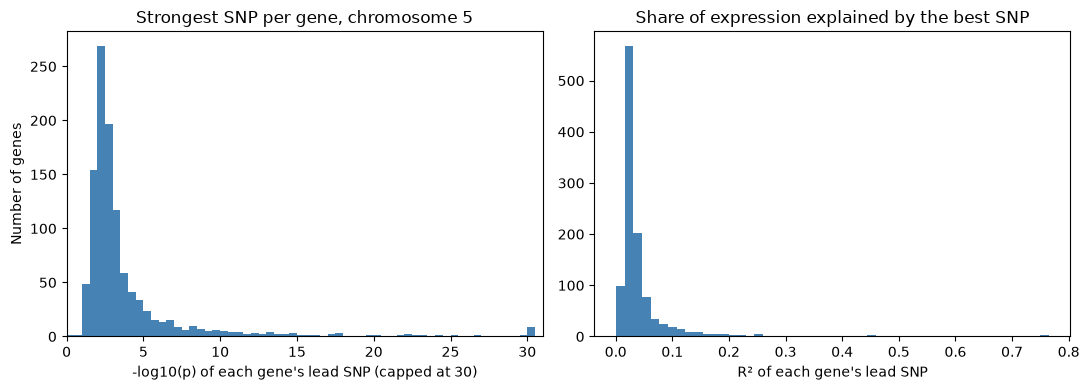

Median lead R²: 0.027
Genes where the best SNP explains over 10%: 76


In [6]:
figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(11, 4))

lead_neg_log10_p = np.minimum(-np.log10(gene_results["lead_p_value"].to_numpy()), 30)
left_axis.hist(lead_neg_log10_p, bins=np.arange(0, 31, 0.5), color="steelblue")
left_axis.set_xlim(0, 31)
left_axis.set_xlabel("-log10(p) of each gene's lead SNP (capped at 30)")
left_axis.set_ylabel("Number of genes")
left_axis.set_title("Strongest SNP per gene, chromosome 5")

right_axis.hist(gene_results["lead_r_squared"], bins=50, color="steelblue")
right_axis.set_xlabel("R² of each gene's lead SNP")
right_axis.set_title("Share of expression explained by the best SNP")
plt.tight_layout()
plt.show()

print("Median lead R²:", gene_results["lead_r_squared"].median().round(3))
print("Genes where the best SNP explains over 10%:", (gene_results["lead_r_squared"] > 0.10).sum())

**What I see:** Most genes pile up at the low end: their best SNP has a modest p-value and explains only a few percent of expression (the median lead R² is about 0.03). A smaller group (76 genes where the best SNP explains over 10%) of genes has very strong eQTLs, stretching far to the right. So a handful of genes are strongly controlled by a nearby SNP, while most genes have weak or no detectable cis effects in this data.

One caution: every gene's "best SNP" is the best of about 400 tries, so even a gene with no real eQTL will show a lead R² of a few percent just by luck. That's why the Bonferroni cutoff matters.

## Task 2: Building an expression score with P+T

The task follows the PLINK PRS tutorial, which uses a height GWAS (`Height.QC.gz`) as a stand-in for eQTL results. The steps are the same either way: clump, threshold, score. Here I run them on my real eQTL results for ERAP2, so the "GWAS" is ERAP2's eQTL summary statistics. I build the height PRS itself in Week 5, when I score the 1000 Genomes people and the 23andMe sample.

The PLINK version of these steps:

```bash
plink --bfile 1000G.EUR.5 --clump-p1 1 --clump-r2 0.1 --clump-kb 250 --clump erap2_eqtl.txt --clump-snp-field SNP --clump-field P --out erap2
plink --bfile 1000G.EUR.5 --score erap2_eqtl.txt 1 2 3 header --q-score-range range_list snp_pvalue.txt --extract erap2.valid.snp --out erap2_score
```

### Step 6: Clumping

In [7]:
clump_window = 250_000
clump_ld_cutoff = 0.1

def clump(snp_p_values, snp_window_positions, snp_genotypes):
    standardized = snp_genotypes - snp_genotypes.mean(axis=0)
    lengths = np.linalg.norm(standardized, axis=0)
    lengths[lengths == 0] = np.inf
    standardized = standardized / lengths

    still_available = np.ones(len(snp_p_values), dtype=bool)
    kept = np.zeros(len(snp_p_values), dtype=bool)

    for snp in np.argsort(snp_p_values, kind="stable"):
        if not still_available[snp]:
            continue
        kept[snp] = True
        still_available[snp] = False
        nearby = np.flatnonzero(still_available & (np.abs(snp_window_positions - snp_window_positions[snp]) <= clump_window))
        ld_r_squared = (standardized[:, nearby].T @ standardized[:, snp]) ** 2
        still_available[nearby[ld_r_squared > clump_ld_cutoff]] = False
    return kept


def build_expression_score(score_genotypes, score_expression, window_positions):
    snp_stats = regress_expression_on_snps(score_expression, score_genotypes)
    snp_stats["column"] = np.arange(score_genotypes.shape[1])
    snp_stats = snp_stats.dropna(subset=["p_value"]).reset_index(drop=True)
    columns = snp_stats["column"].to_numpy()
    kept = clump(snp_stats["p_value"].to_numpy(), window_positions[columns], score_genotypes[:, columns])
    return snp_stats[kept].reset_index(drop=True)


erap2_positions = snp_positions[erap2_columns]
erap2_genotypes = genotypes[:, erap2_columns]

erap2_clumped = build_expression_score(erap2_genotypes, erap2_expression, erap2_positions)
erap2_clumped.insert(0, "snp_id", snp_table["snp_id"].to_numpy()[erap2_columns][erap2_clumped["column"]])

print("ERAP2 SNPs before clumping:", len(erap2_columns))
print("After clumping:", len(erap2_clumped))
erap2_clumped.sort_values("p_value").head(8)

ERAP2 SNPs before clumping: 510
After clumping: 50


,snp_id,slope,p_value,r_squared,column
33,rs2762,15.450085,1.642397e-109,0.764777,356
37,rs31019,-4.799061,4.467427e-08,0.083925,411
26,rs26498,-6.038693,5.291720e-08,0.083044,277
22,rs152019,-5.664507,1.507576e-07,0.077584,173
34,rs11746232,-6.826995,1.391999e-06,0.065930,380
19,rs155046,4.642552,4.923186e-06,0.059274,133
25,rs10050860,4.457036,2.667241e-05,0.050346,260
27,rs3734016,8.552456,1.308391e-04,0.041935,280


**What I see:** Clumping cuts ERAP2's 510 SNPs down to about 50. The other SNPs were removed because they were in LD with a stronger SNP nearby, so they mostly carried the same signal. The top clumped SNP is from the lead tower, and only one of the five tied SNPs survives, which is exactly the double counting clumping is meant to prevent.

### Step 7: Thresholding and scoring (all 344 people)

In [8]:
p_thresholds = [1, 0.05, 0.01, 0.001, 0.00001]

def predict_expression(score_genotypes, clumped_snps, p_threshold):
    """Score = sum of (copies x slope) over clumped SNPs with p below the threshold (1 = use all)."""
    chosen = clumped_snps if p_threshold >= 1 else clumped_snps[clumped_snps["p_value"] < p_threshold]
    if chosen.empty:
        return np.zeros(score_genotypes.shape[0]), 0
    return score_genotypes[:, chosen["column"].to_numpy()] @ chosen["slope"].to_numpy(), len(chosen)


def prediction_accuracy(predicted, observed):
    """Correlation r and R² between predicted and real expression (0 if the prediction is flat)."""
    if np.std(predicted) == 0:
        return np.nan, 0.0
    r = np.corrcoef(predicted, observed)[0, 1]
    return r, r ** 2


def threshold_table(score_genotypes, score_expression, clumped_snps):
    rows = []
    for p_threshold in p_thresholds:
        predicted, number_of_snps = predict_expression(score_genotypes, clumped_snps, p_threshold)
        r, r_squared = prediction_accuracy(predicted, score_expression)
        rows.append({"p_threshold": p_threshold, "snps_in_score": number_of_snps, "r": r, "r_squared": r_squared})
    return pd.DataFrame(rows)


same_people_table = threshold_table(erap2_genotypes, erap2_expression, erap2_clumped)
same_people_table.round({"r": 3, "r_squared": 3})

,p_threshold,snps_in_score,r,r_squared
0,1.00000,50,0.788,0.621
1,0.05000,24,0.778,0.606
2,0.01000,17,0.788,0.620
3,0.00100,10,0.787,0.620
4,0.00001,6,0.809,0.654


**What I see:** Every threshold explains about 60% to 65% of ERAP2 expression. The strictest threshold (p < 0.00001, about 6 SNPs) does best, and adding more SNPs doesn't help, because ERAP2 is controlled mostly by one strong signal.

But this is the overfitting trap: I found the slopes in these 344 people and scored the same 344 people. The next task fixes that.

## Task 3: Cross-validation for ERAP2

### Step 8: Split people into training, tuning, and testing

I use a fixed random seed so the split is the same every time I run this. In PLINK, each group would be a text file of IDs passed with `--keep`.

In [9]:
random_generator = np.random.default_rng(2026)
shuffled_people = list(random_generator.permutation(shared_people))

number_training = round(0.8 * len(shuffled_people))
number_tuning = round(0.1 * len(shuffled_people))

people_groups = {
    "training": shuffled_people[:number_training],
    "tuning": shuffled_people[number_training:number_training + number_tuning],
    "testing": shuffled_people[number_training + number_tuning:],
}

row_of_person = {person: row for row, person in enumerate(shared_people)}
group_rows = {name: np.array([row_of_person[person] for person in people]) for name, people in people_groups.items()}

for name, people in people_groups.items():
    print(f"{name}: {len(people)} people")
print("Any person in two groups?", len(set.union(*map(set, people_groups.values()))) != len(shared_people))

training: 275 people
tuning: 34 people
testing: 35 people
Any person in two groups? False


**What I see:** I see 275 people in training, 34 in tuning, and 35 in testing, and no one is in more than one group.

### Step 9: Fit on training, pick a threshold on tuning, check on testing

In [10]:
def cross_validate(gene_genotypes, gene_expression, window_positions):
    training_rows, tuning_rows, testing_rows = group_rows["training"], group_rows["tuning"], group_rows["testing"]

    # 1. Training: eQTL slopes and p-values, then clumping (LD from training people only)
    clumped_snps = build_expression_score(gene_genotypes[training_rows], gene_expression[training_rows], window_positions)

    # 2. Tuning: try each threshold, keep the best R² (ties go to the stricter threshold)
    tuning_table = threshold_table(gene_genotypes[tuning_rows], gene_expression[tuning_rows], clumped_snps)
    best = tuning_table.sort_values(["r_squared", "p_threshold"], ascending=[False, True]).iloc[0]

    # 3. Testing: one final check with the chosen threshold
    test_predicted, snps_in_score = predict_expression(gene_genotypes[testing_rows], clumped_snps, best["p_threshold"])
    test_r, test_r_squared = prediction_accuracy(test_predicted, gene_expression[testing_rows])

    summary = {"clumped_snps": len(clumped_snps), "best_p_threshold": best["p_threshold"],
               "tuning_r_squared": best["r_squared"], "snps_in_score": snps_in_score,
               "test_r": test_r, "test_r_squared": test_r_squared}
    return summary, tuning_table, test_predicted


erap2_summary, erap2_tuning_table, erap2_test_predicted = cross_validate(erap2_genotypes, erap2_expression, erap2_positions)

print("Tuning results:")
print(erap2_tuning_table.round({"r": 3, "r_squared": 3}).to_string(index=False))
print()
for key, value in erap2_summary.items():
    print(f"{key}: {value:.3g}" if isinstance(value, float) else f"{key}: {value}")

Tuning results:
 p_threshold  snps_in_score     r  r_squared
     1.00000             51 0.731      0.535
     0.05000             24 0.769      0.592
     0.01000             12 0.776      0.602
     0.00100              9 0.764      0.584
     0.00001              5 0.814      0.662

clumped_snps: 51
best_p_threshold: 1e-05
tuning_r_squared: 0.662
snps_in_score: 5
test_r: 0.831
test_r_squared: 0.69


**What I see:** Using only the 275 training people, clumping kept 51 SNPs. On the tuning group, the strictest threshold (p < 0.00001, 5 SNPs) gave the best R² (about 0.66), so that's the one I chose. On the 35 testing people, who were never used for anything, the score has r = 0.83 and **R² = 0.69**. So genotype alone predicts about 69% of the differences in ERAP2 expression in new people.

The test R² is close to the all-people R² from Step 7 (about 0.65), so for ERAP2 overfitting wasn't a big problem. That makes sense: its eQTL is so strong that even 275 people find it clearly. The test group is only 35 people, though, so 0.69 is a rough estimate (it could easily be 0.55 or 0.80 with a different split).

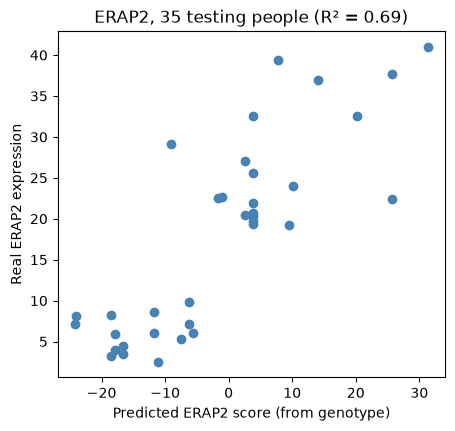

In [11]:
erap2_test_real = erap2_expression[group_rows["testing"]]

plt.figure(figsize=(5, 4.5))
plt.scatter(erap2_test_predicted, erap2_test_real, color="steelblue")
plt.xlabel("Predicted ERAP2 score (from genotype)")
plt.ylabel("Real ERAP2 expression")
plt.title(f"ERAP2, 35 testing people (R² = {erap2_summary['test_r_squared']:.2f})")
plt.show()

**What I see:** The dots rise from left to right. People with negative scores almost all have low real expression (under about 10), and people with positive scores mostly have 20 to 40. Several people share exactly the same score, because the score uses only 5 SNPs, so people with the same genotypes at those 5 get the same number. The spread within each score shows the part of ERAP2 expression that genotype doesn't explain.

## Gradescope question 4: How well does genotype predict expression across all genes?

### Step 10: Cross-validate every gene on chromosome 5

Same split, same steps, repeated for all 1,091 genes. This takes a minute or two.

In [12]:
cv_results = []

for gene_id, gene_info in genes_on_chromosome.iterrows():
    window_columns = cis_window_columns(int(gene_info["Coord"]))
    if len(window_columns) == 0:
        continue
    gene_expression = expression_table.loc[gene_id, shared_people].to_numpy(dtype=float)
    summary, _, _ = cross_validate(genotypes[:, window_columns], gene_expression, snp_positions[window_columns])
    summary["gene_id"] = gene_id
    cv_results.append(summary)

cv_results = pd.DataFrame(cv_results).merge(gene_results[["gene_id", "is_egene"]], on="gene_id")

print("Genes:", len(cv_results))
print("Genes with a flat prediction (no SNPs in the score):", cv_results["test_r"].isna().sum())
cv_results.groupby("is_egene")["test_r"].describe().round(3)

Genes: 1091
Genes with a flat prediction (no SNPs in the score): 9


,count,mean,std,min,25%,50%,75%,max
is_egene,,,,,,,,
False,827.0,0.009,0.173,-0.467,-0.114,0.003,0.129,0.516
True,255.0,0.230,0.223,-0.411,0.070,0.218,0.369,0.831


**What I see:** Across all chromosome 5 genes, the test correlation is centered near 0 (median about 0.05). Splitting by eGene status shows why:
- **eGenes (255 with a prediction; 3 had no SNPs pass the chosen threshold):** median test r about 0.22, and about 86% are above 0. Their predictions mostly work.
- **Non-eGenes:** median test r about 0, and only about half are above 0. That's what pure chance looks like, so for these genes the score isn't predicting anything.

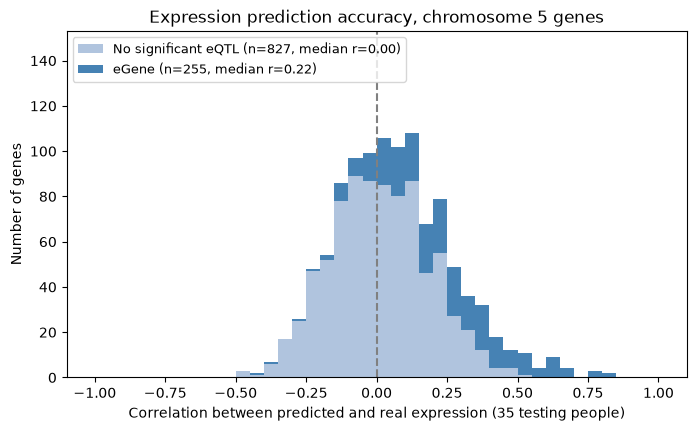

In [13]:
bins = np.linspace(-1, 1, 41)
egene_r = cv_results.loc[cv_results["is_egene"], "test_r"].dropna()
other_r = cv_results.loc[~cv_results["is_egene"], "test_r"].dropna()

plt.figure(figsize=(8, 4.5))
plt.hist([other_r, egene_r], bins=bins, stacked=True, color=["lightsteelblue", "steelblue"],
         label=[f"No significant eQTL (n={len(other_r)}, median r={other_r.median():.2f})",
                f"eGene (n={len(egene_r)}, median r={egene_r.median():.2f})"])
plt.axvline(0, color="gray", linestyle="--")
plt.xlabel("Correlation between predicted and real expression (35 testing people)")
plt.ylabel("Number of genes")
plt.title("Expression prediction accuracy, chromosome 5 genes")
plt.ylim(0, plt.ylim()[1] * 1.35)
plt.legend(loc="upper left", fontsize=9)
plt.show()

**What I see:** The non-eGenes (light) form a wide bell centered at 0, from about -0.5 to 0.5. With only 35 testing people, a correlation that big can happen by chance alone. The eGenes (dark) are shifted to the right, with a tail of genes predicted very well, including ERAP2 at 0.83.

So genotype predicts expression well for a small set of genes with strong cis-eQTLs, and barely at all for most genes. One limitation: I labeled eGenes using all 344 people, including the testing people, so the eGene split slightly favors the eGenes. The overall distribution doesn't use that label.

## Readings guide

---

### GTEx Consortium 2020, *Science* (reread): comparing their methods to mine

**What it's about:** The same paper as Week 3. This time I read it for **how** they ran the analysis, since my Quarter 1 project replicates a smaller version of it.

**My notes:**
- They map cis-eQTLs separately in each of 49 tissues, then combine results across tissues.
- They correct expression for hidden factors and covariates (like ancestry and sex) before testing. My expression file already has 10 hidden factors removed ("resk10" in the file name), but I don't include ancestry or sex.
- They use FDR (5%) to call eGenes, which is less strict than my Bonferroni cutoff, so they call more eGenes.
- Many genes have more than one independent eQTL. My lead-SNP approach only captures the strongest one, but P+T can include more than one signal.
- They use PrediXcan to build expression scores and link them to 87 GWAS traits. My Task 2 and 3 is a simpler version of the same idea.
- Sample size drives everything: the number of eGenes found tracks very closely with how many people each tissue has.

**My analysis vs. GTEx:**
| | GTEx | Me |
|---|---|---|
| People | 838 donors (70+ per tissue) | 344 |
| Tissues | 49 | 1 (lab-grown blood cells, LCLs) |
| Variants | Whole genome sequencing, about 10 million common | About 1.2 million mostly common SNPs |
| cis window | ±1 Mb around the gene's start | ±500 kb around one gene position |
| Covariates | Ancestry, sex, hidden factors | Hidden factors already removed in the file |
| Significance | FDR 5% per tissue | Bonferroni per gene |
| eGenes | Almost all genes in at least one tissue | 24% of chromosome 5 genes |

## Week 4 answers

### Task questions

**1. cis-eQTLs for all genes on one chromosome.**
I tested the 1,091 chromosome 5 genes that have SNPs in their window (344 people, SNPs within ±500 kb). 258 genes (24%) had at least one SNP past their own Bonferroni cutoff. ERAP2 was the strongest (p = 1.6e-109).

**2. PRS with P+T.**
For ERAP2, clumping (r² > 0.1 within 250 kb) cut 510 SNPs to about 50. Scoring all 344 people at thresholds 1 to 0.00001 explained about 60% to 65% of ERAP2 expression, best at the strictest threshold. This is measured on the same people the slopes came from, so it can be inflated.

**3. Cross-validation for ERAP2.**
With an 80/10/10 split (275 / 34 / 35 people), the tuning group picked p < 0.00001 (5 SNPs). On the 35 testing people, the score had r = 0.83 and a final **R² = 0.69**.

### Gradescope questions

**1. What is the biological purpose of understanding how genetic variation affects gene expression?**
Most SNPs linked to disease in GWAS are not inside genes. They sit in the regions that control how much a gene is used. On their own, these GWAS hits don't explain how they cause disease. Mapping eQTLs connects a disease SNP to the specific gene it turns up or down, and in which tissues, which points to the biological mechanism. For example, GTEx found that GWAS SNPs are more likely to be eQTLs than random SNPs, and that about 43% of GWAS loci share a causal signal with an eQTL. Knowing the gene and direction of the effect can point to drug targets, and lets us predict expression from DNA alone, which can then be used to find genes linked to disease in large GWAS.

**2. What would be a good title for a paper on this capstone analysis?**
"From Genotype to Gene Expression to Disease: Mapping cis-eQTLs and Building Polygenic Risk Scores in 1000 Genomes"

**3. What should the paper's introduction cover?**
- **The problem:** most disease-linked variants are outside genes, so we don't know how they work.
- **GWAS:** what they are, what they've found, and that most hits are in regulatory regions.
- **eQTLs:** what they are, how they link variants to genes and tissues, and what GTEx found.
- **Genetic risk scores:** adding up many small effects to predict a trait. They can predict a gene's expression or a person's disease risk, and could help in preventive care.
- **Limits:** scores work worse in non-European ancestries, and most data is European.
- **My study:** genome-wide cis-eQTLs in 1000 Genomes LCLs, prediction of expression, and PRS for diseases, including where one 23andMe sample falls on the distribution.

**4. What was the distribution of correlations between true and predicted gene expression across genes in 1000 Genomes?**
Across 1,091 genes on chromosome 5, using 35 held-out testing people, the correlation between predicted and real expression was centered near zero (median about 0.05). It was very different by gene type. Genes with a significant cis-eQTL had a median correlation of about 0.22, and about 86% were above zero, with a tail of very well predicted genes like ERAP2 (r = 0.83). Genes without a significant eQTL had a median of about 0, with about half above and half below zero, which is what chance looks like. So genotype predicts expression well for a small set of genes with strong cis-eQTLs, but not for most genes. With only 35 testing people, each gene's value is noisy, so the overall pattern is more reliable than any single gene.